C:\Users\ANUBHAV\AppData\Local\Temp\ipykernel_24972\4099818186.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


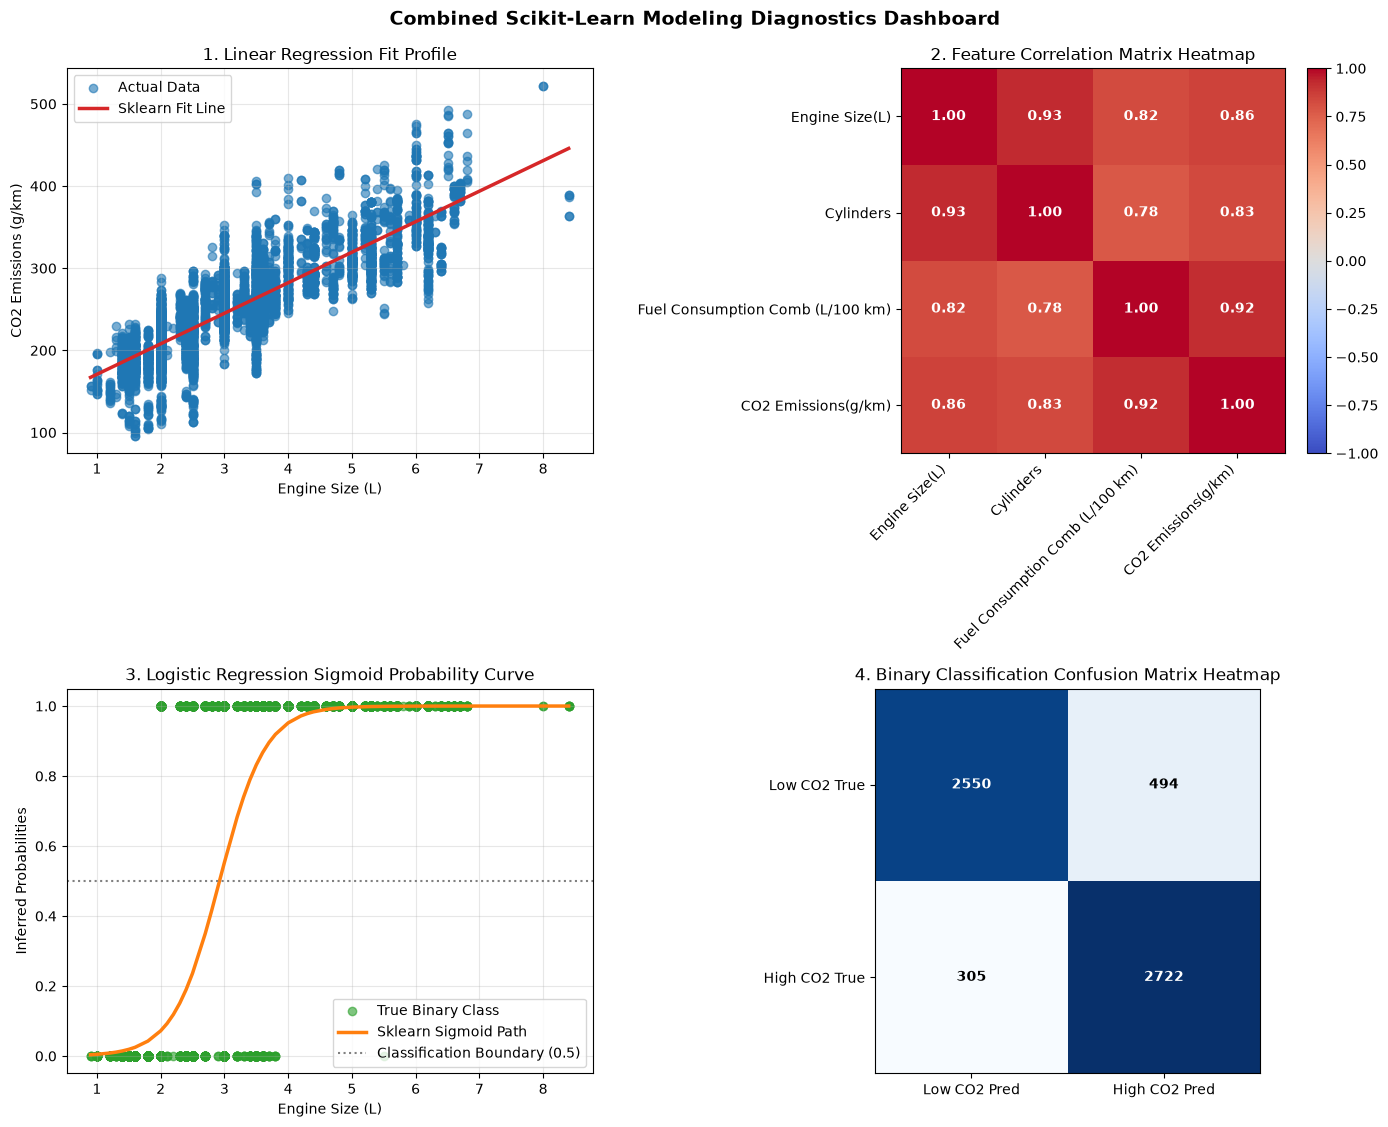


      SKLEARN PIPELINE ANALYSIS RESULTS REPORT     
Linear Regression Fit  -> MAE: 23.0906
                       -> RMSE: 30.5566
                       -> R² Variance Score: 0.7341
--------------------------------------------------
Logistic Regression    -> Target Binarization Threshold Level:  245.0 g/km
                       -> Binary Target Classification Accuracy: 86.84%



In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. DATA LOADING & CLEANING
# ==========================================
def load_and_clean_data(file_path="co2(1).csv"):
    df = pd.read_csv(file_path)

    # Discard redundant repeated fuel consumption columns
    columns_to_drop = [
        "Fuel Consumption City (L/100 km)",
        "Fuel Consumption Hwy (L/100 km)",
        "Fuel Consumption Comb (mpg)"
    ]
    df = df.drop(columns=columns_to_drop, errors="ignore")

    # Remove duplicates and clean text whitespace/casing
    df = df.drop_duplicates()
    text_columns = df.select_dtypes(include="object").columns
    for col in text_columns:
        df[col] = df[col].str.lower().str.strip()
        
    return df

# ==========================================
# 2. MODELING FUNCTIONS
# ==========================================
def run_linear_regression(X, Y):
    """Trains a Linear Regression model and evaluates its metrics."""
    model = LinearRegression()
    model.fit(X, Y)
    Y_pred = model.predict(X)
    
    # Calculate performance metrics
    metrics = {
        "MAE": mean_absolute_error(Y, Y_pred),
        "RMSE": np.sqrt(mean_squared_error(Y, Y_pred)),
        "R2": r2_score(Y, Y_pred)
    }
    return model, Y_pred, metrics


def run_logistic_regression(X, Y):
    """Binarizes target at the median, scales features, and trains Logistic Regression."""
    # Create high vs low CO2 classes based on the median threshold
    threshold = np.median(Y)
    Y_binary = (Y > threshold).astype(int)
    
    # Scale features for stable optimization convergence
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    model = LogisticRegression(solver="lbfgs")
    model.fit(X_scaled, Y_binary)
    
    # Generate predictions and probabilities
    predictions = model.predict(X_scaled)
    probabilities = model.predict_proba(X_scaled)[:, 1]
    
    # Calculate performance metrics
    metrics = {
        "Accuracy": accuracy_score(Y_binary, predictions),
        "Confusion_Matrix": confusion_matrix(Y_binary, predictions)
    }
    return model, Y_binary, predictions, probabilities, metrics

# ==========================================
# 3. VISUALISATION DASHBOARD
# ==========================================
def plot_diagnostic_dashboard(df, X, Y, Y_pred, Y_binary, probs, cm):
    """Generates a 2x2 grid of regression, correlation, and classification diagnostics."""
    fig, axs = plt.subplots(2, 2, figsize=(14, 11))
    X_flat = X.flatten()
    sort_idx = np.argsort(X_flat)
    
    # Plot 1: Linear Regression Best Fit Line
    axs[0, 0].scatter(X_flat, Y, color="tab:blue", alpha=0.6, label="Actual Data")
    axs[0, 0].plot(X_flat[sort_idx], Y_pred[sort_idx], color="tab:red", lw=2.5, label="Sklearn Fit Line")
    axs[0, 0].set_xlabel("Engine Size (L)")
    axs[0, 0].set_ylabel("CO2 Emissions (g/km)")
    axs[0, 0].set_title("1. Linear Regression Fit Profile")
    axs[0, 0].legend()
    axs[0, 0].grid(True, alpha=0.3)
    
    # Plot 2: Correlation Matrix Heatmap
    corr_matrix = df.corr(numeric_only=True)
    cax_corr = axs[0, 1].imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    fig.colorbar(cax_corr, ax=axs[0, 1], fraction=0.046, pad=0.04) # Clean layout alignment spacing
    
    ticks = np.arange(len(corr_matrix.columns))
    axs[0, 1].set_xticks(ticks)
    axs[0, 1].set_yticks(ticks)
    axs[0, 1].set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
    axs[0, 1].set_yticklabels(corr_matrix.columns)
    axs[0, 1].set_title("2. Feature Correlation Matrix Heatmap")
    
    # Annotate correlation values inside the heatmap cells
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            axs[0, 1].text(
                j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center", va="center", weight="bold",
                color="white" if abs(corr_matrix.iloc[i, j]) > 0.5 else "black"
            )
    
    # Plot 3: Logistic Regression Sigmoid Probability Curve
    axs[1, 0].scatter(X_flat, Y_binary, color="tab:green", alpha=0.6, label="True Binary Class")
    axs[1, 0].plot(X_flat[sort_idx], probs[sort_idx], color="tab:orange", lw=2.5, label="Sklearn Sigmoid Path")
    axs[1, 0].axhline(0.5, color="gray", linestyle=":", label="Classification Boundary (0.5)")
    axs[1, 0].set_xlabel("Engine Size (L)")
    axs[1, 0].set_ylabel("Inferred Probabilities")
    axs[1, 0].set_title("3. Logistic Regression Sigmoid Probability Curve")
    axs[1, 0].legend()
    axs[1, 0].grid(True, alpha=0.3)
    
    # Plot 4: Confusion Matrix Heatmap
    axs[1, 1].imshow(cm, cmap="Blues", interpolation="nearest")
    axs[1, 1].set_xticks([0, 1])
    axs[1, 1].set_yticks([0, 1])
    axs[1, 1].set_xticklabels(["Low CO2 Pred", "High CO2 Pred"])
    axs[1, 1].set_yticklabels(["Low CO2 True", "High CO2 True"])
    axs[1, 1].set_title("4. Binary Classification Confusion Matrix Heatmap")
    
    # Overlay the quadrant counts inside the matrix text spaces
    for i in range(2):
        for j in range(2):
            axs[1, 1].text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center", weight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )
            
    plt.tight_layout()
    plt.suptitle("Combined Scikit-Learn Modeling Diagnostics Dashboard", fontsize=14, weight="bold", y=1.02)
    plt.show()

# ==========================================
# 4. MAIN PIPELINE EXECUTION
# ==========================================
if __name__ == "__main__":
    # Load and prep data arrays
    df_clean = load_and_clean_data("co2(1).csv")
    X_features = df_clean[["Engine Size(L)"]].values
    Y_target = df_clean["CO2 Emissions(g/km)"].values
    
    # Run algorithms
    _, lin_preds, lin_metrics = run_linear_regression(X_features, Y_target)
    _, log_target, _, log_probs, log_metrics = run_logistic_regression(X_features, Y_target)
    
    # Render diagnostics graphics matrix
    plot_diagnostic_dashboard(
        df=df_clean,
        X=X_features, 
        Y=Y_target, 
        Y_pred=lin_preds, 
        Y_binary=log_target, 
        probs=log_probs, 
        cm=log_metrics["Confusion_Matrix"]
    )
    
    # Print metrics dashboard output breakdown logs
    print("\n" + "="*50)
    print("      SKLEARN PIPELINE ANALYSIS RESULTS REPORT     ")
    print("="*50)
    print(f"Linear Regression Fit  -> MAE: {lin_metrics['MAE']:.4f}")
    print(f"                       -> RMSE: {lin_metrics['RMSE']:.4f}")
    print(f"                       -> R² Variance Score: {lin_metrics['R2']:.4f}")
    print("-"*50)
    print(f"Logistic Regression    -> Target Binarization Threshold Level:  {np.median(Y_target)} g/km")
    print(f"                       -> Binary Target Classification Accuracy: {log_metrics['Accuracy']*100:.2f}%")
    print("="*50 + "\n")
